In [1]:
import numpy as np
from numba import njit, prange
import matplotlib.pyplot as plt
import matplotlib
import pymc as pm
import pytensor.tensor as pt
import arviz as az
from tqdm.notebook import tqdm
import matplotlib.patches as mpatches
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KernelDensity
from sklearn.preprocessing import StandardScaler
from tools import load_csv

# Axis `F = F[sample, time]`
_______

In [2]:
kbT = 4.112
eps = 1e-14

In [43]:
data = [
        #dict(filename='stiff80_2.csv', stiffness=80, ru=0.15, xu=0.2, dropout_force = 0.),
        dict(filename='stiff40_2.csv', stiffness=40, ru=0.15, xu=0.2, dropout_force = 0.),
        #dict(filename='stiff20_2.csv', stiffness=20, ru=0.15, xu=0.2, dropout_force = 0.),
        #dict(filename='stiff80_2.csv', stiffness=80, ru=0.15, xu=0.2, dropout_force = 2.),
        dict(filename='stiff40_2.csv', stiffness=40, ru=0.15, xu=0.2, dropout_force = 2.),
        #dict(filename='stiff20_2.csv', stiffness=20, ru=0.15, xu=0.2, dropout_force = 2.),
        
       ]

data = [#dict(filename='stiff80_1.csv', stiffness=80, ru=0.01, xu=0.8, dropout_force = 2.),
        #dict(filename='stiff40_1.csv', stiffness=40, ru=0.01, xu=0.8, dropout_force = 2.),
        #dict(filename='stiff20_1.csv', stiffness=20, ru=0.01, xu=0.8, dropout_force = 2.),
        dict(filename='stiff80_2.csv', stiffness=80, ru=0.15, xu=0.2, dropout_force = 2.),
        dict(filename='stiff40_2.csv', stiffness=40, ru=0.15, xu=0.2, dropout_force = 2.),
        dict(filename='stiff20_2.csv', stiffness=20, ru=0.15, xu=0.2, dropout_force = 2.),
        #dict(filename='stiff80_4_all.csv', stiffness=80, ru=0.15, xu=0.8, dropout_force = 2.),
        #dict(filename='stiff40_4_all.csv', stiffness=40, ru=0.15, xu=0.8, dropout_force = 2.),
        #dict(filename='stiff20_4_all.csv', stiffness=20, ru=0.15, xu=0.8, dropout_force = 2.),
        #dict(filename='stiff80_4_first.csv', stiffness=80, ru=0.15, xu=0.8, dropout_force = 0.),
        #dict(filename='stiff40_4_first.csv', stiffness=40, ru=0.15, xu=0.8, dropout_force = 0.),
        #dict(filename='stiff20_4_first.csv', stiffness=20, ru=0.15, xu=0.8, dropout_force = 0.),
       ]

figsize=(10,10)
nrows=3
ncols=3

for d_ in data:
    d_.update(load_csv(d_['filename'], clip_low_forces=False))

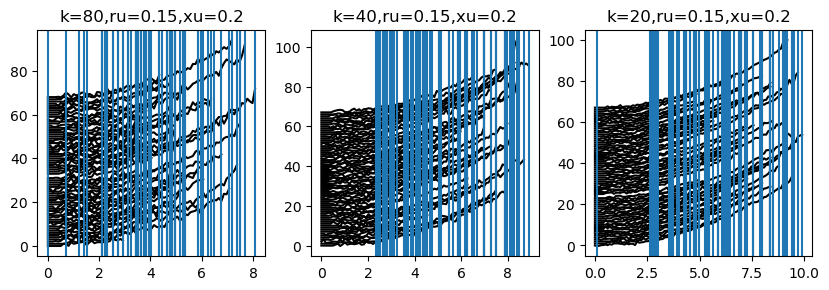

In [44]:
def plot_force_curves(data, offset=1, plot_events=True, alpha=1, color='k'):
    F = data['F']
    t = data['t']
    if plot_events:
        E = data['events']
    for i, f in enumerate(F):
        plt.plot(t, f + offset*i, color=color, alpha=alpha)
    if plot_events:
        for e in E:
            plt.axvline(t[e])

plt.figure(figsize=figsize)
for i, d_ in enumerate(data):
    plt.subplot(nrows, ncols, i+1)
    plot_force_curves(d_)
    plt.title(f"k={d_['stiffness']},ru={d_['ru']},xu={d_['xu']}")

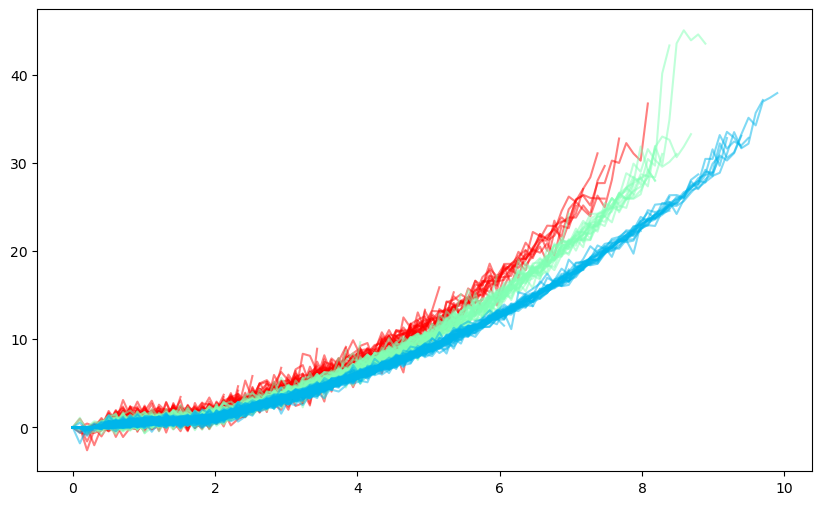

In [45]:
cmap = matplotlib.colormaps.get_cmap("rainbow")

plt.figure(figsize=(10,6))
for i, d_ in enumerate(data):
    col = cmap(d_['stiffness']/80)
    plot_force_curves(d_, alpha=0.5, offset=False, plot_events=False, color=col)

In [46]:
def plot_event_hist(data, offset=1, alpha=1, color='k', bins=None):
    event_t = data['events_t']
    plt.hist(event_t, density=True, color=color, alpha=alpha, bins=bins)

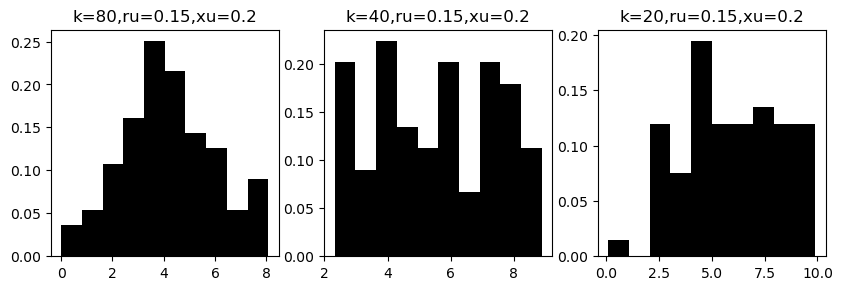

In [47]:
plt.figure(figsize=figsize)
for i, d_ in enumerate(data):
    plt.subplot(nrows, ncols, i+1)
    plot_event_hist(d_)
    plt.title(f"k={d_['stiffness']},ru={d_['ru']},xu={d_['xu']}")

0
1
2


/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_68333/3859838719.py:3: RuntimeWarning: Mean of empty slice
  F = np.nanmean(data['F'].copy(), axis=0)


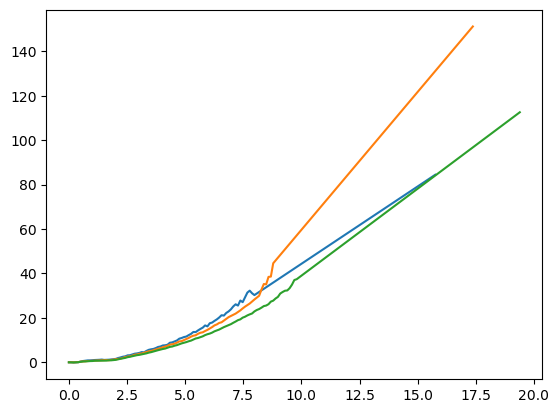

In [48]:
def mean_force_curve(data):
    t = data['t'].copy()
    F = np.nanmean(data['F'].copy(), axis=0)
    last_idx = np.argmax(np.isnan(F))
    F = F[:last_idx-1]
    t = t[:last_idx-1]
    return dict(t=t.copy(), F=F.copy(), ru=data['ru'], xu=data['xu'], dt=data['dt'].copy())

def extend_force_curve(d, rel_additional_time=1, n_interpolation_count=20):
    t = d['t']
    tmax = t[-1]
    F = d['F']
    dt = d['dt']
    slope = (F[-1] - F[-n_interpolation_count-1]) / (n_interpolation_count * dt)

    idx_ext = np.arange(1, int(tmax*rel_additional_time/dt))
    t_ext = tmax + idx_ext * dt
    F_ext = F[-1] + idx_ext * dt * slope

    F_new = np.concatenate((F, F_ext))
    t_new = np.concatenate((t, t_ext))
    d['t'] = t_new
    d['F'] = F_new
    

for i, d_ in enumerate(data):
    print(i)
    model = mean_force_curve(d_)
    extend_force_curve(model)
    plt.plot(model['t'], model['F']+0*i)

/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_68333/3859838719.py:3: RuntimeWarning: Mean of empty slice
  F = np.nanmean(data['F'].copy(), axis=0)


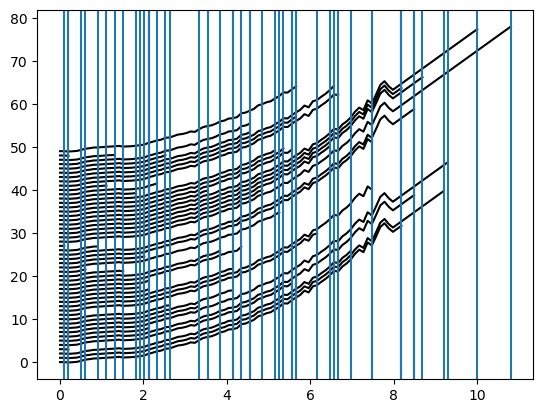

In [49]:
def simulate_samples(N, model):
    t_m = model['t'].copy()
    tidx = np.arange(t_m.shape[0])
    F_m = model['F'].copy()
    ru_m = model['ru']
    xu_m = model['xu']
    dt_m = model['dt']

    F = F_m.copy()[np.newaxis, :].repeat(N, axis=0)
    events = -1*np.ones(N, dtype=int)

    for sample in range(N):
        for t in tidx:
            f = F[sample, t]
            pu = dt_m * ru_m * np.exp(xu_m * f / kbT)
            a = np.random.rand()
            if pu > a:
                events[sample] = t
                F[sample, t+1:] = np.nan
                break

    events_t = t_m[events]
    return dict(F=F, t=t_m, events=events, events_t=events_t, ru=ru_m, xu=xu_m, dt=dt_m)

model = mean_force_curve(data[0])
extend_force_curve(model, rel_additional_time=1)
res = simulate_samples(50 ,model)
plot_force_curves(res, plot_events=True)
#plot_force_curves(data[0])

In [50]:
@njit
def rejection_probability_core(dropout_force, t_m, tidx, F_m, ru_m, xu_m, dt_m, N):
    rejections = 0
    for s in prange(N):
        for t in tidx:
            f = F_m[t]
            pu = 1 - np.exp(-dt_m * ru_m * np.exp(xu_m * f / kbT))
            a = np.random.rand()
            if pu > a:
                if f < dropout_force:
                    rejections += 1
                    break
    
    return rejections / N

@njit
def rejection_probability_core_fast(dropout_force, t_m, tidx, F_m, ru_m, xu_m, dt_m, N):
    p_dropout = 0
    p_cum = 1
    for t in tidx:
        f = F_m[t]
        pu = np.exp(-dt_m * ru_m * np.exp(xu_m * f / kbT))

        if f < dropout_force:
            p_dropout += p_cum * (1 - pu)

        p_cum *= pu
    
    return p_dropout
        
def rejection_probability(model, dropout_force, ru_m=None, xu_m=None, N=1000):
    t_m = model['t']
    tidx = np.arange(t_m.shape[0])
    F_m = model['F']
    
    if ru_m is None:
        ru_m = model['ru']

    if xu_m is None:
        xu_m = model['xu']
    dt_m = model['dt']
    return rejection_probability_core_fast(dropout_force, t_m, tidx, F_m, ru_m, xu_m, dt_m, N)
    
rejection_probability(model, dropout_force=2, N=100)

0.29321884065954784

In [51]:
def integrate_decay(model):
    t_m = model['t'].copy()
    tidx = np.arange(t_m.shape[0])
    F_m = model['F'].copy()
    ru_m = model['ru']
    xu_m = model['xu']
    dt_m = model['dt']

    Pt = np.zeros_like(t_m)

    P = 1
    for i in range(len(t_m)):
        #P += -dt_m * P * ru_m * np.exp(xu_m * np.abs(F_m[i]) / kbT) # Euler step is unstable
        P *= np.exp(-dt_m * ru_m * np.exp(xu_m * np.abs(F_m[i]) / kbT)) # "Exact" solution given constant F
        Pt[i] = P

    p = np.gradient(Pt)
    p /= np.sum(p) * dt_m
    model['unbinding_probability'] = p.copy()

integrate_decay(model)

/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_68333/3859838719.py:3: RuntimeWarning: Mean of empty slice
  F = np.nanmean(data['F'].copy(), axis=0)


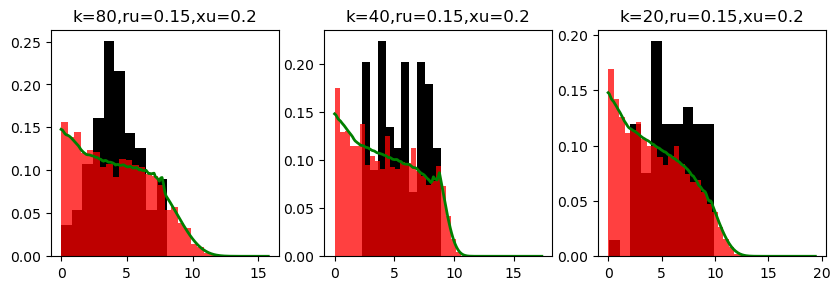

In [52]:
plt.figure(figsize=figsize)
for i, d_ in enumerate(data):
    plt.subplot(nrows, ncols, i+1)
    plot_event_hist(d_, color='k')
    model = mean_force_curve(d_)
    extend_force_curve(model, 1)
    integrate_decay(model)
    sim = simulate_samples(5000, model)
    plot_event_hist(sim, color='r', alpha=0.75, bins=25)
    plt.plot(model['t'], model['unbinding_probability'], 'g', lw=2)
    plt.title(f"k={d_['stiffness']},ru={d_['ru']},xu={d_['xu']}")

---
# Likelihood Calculation

In [53]:
def likelihood(data, ru, xu, dropout_force = None):
    F = data['F']
    n_samples = F.shape[0]
    events = data['events']
    dt = data['dt']
    if dropout_force is None:
        dropout_force = data['dropout_force']
    logpost = likelihood_core(F, events, dt, ru, xu)

    model = mean_force_curve(data)
    extend_force_curve(model, 3)
    p_dropout = rejection_probability(model, ru_m=ru, xu_m=xu, dropout_force=dropout_force, N=1000)
    
    return logpost - n_samples * np.log(1-p_dropout + eps)

@njit(parallel=True)
def likelihood_core(F, events, dt, ru, xu):
    
    n_samples = F.shape[0]
    logpost = 0

    for sample in prange(n_samples):

        len_f = int(events[sample])
        f = F[sample, :len_f]
        
        for t in range(int(events[sample])+1):
            f = F[sample, t]
            p = np.exp(-dt * ru * np.exp(f * xu / kbT))
            logp = -dt * ru * np.exp(f * xu / kbT)
            p = np.exp(logp)
  
            if t  == events[sample]:
                p = 1 - p

            logp = np.log(p+eps)
            logpost += logp
            
    return logpost

def inference(data, n_samples=1000, ru_mutation=1e-3, xu_mutation=1e-3, superstep=100):
    
    ru = data['ru']
    xu = data['xu']

    RU = []
    XU = []
    
    LOGL = -np.inf # Current chain likelihood
    attempts = 0
    accepts = 0
    pbar = tqdm(range(n_samples * superstep), leave=False)
    for s in pbar:
    
        # GIBBS RU
        ru_prop = ru + np.random.randn() * ru_mutation
        
        LOGL_prop = likelihood(data, ru=ru_prop, xu=xu)
        attempts += 1
        thresh = np.exp(LOGL_prop - LOGL)
        a = np.random.rand()
        if a < thresh:
            accepts += 1
            LOGL = LOGL_prop
            ru = ru_prop
    
        # GIBBS XU
        xu_prop = xu + np.random.randn() * xu_mutation
        
        LOGL_prop = likelihood(data, ru=ru, xu=xu_prop)
        attempts += 1
        thresh = np.exp(LOGL_prop - LOGL)
        a = np.random.rand()
        if a < thresh:
            accepts += 1
            LOGL = LOGL_prop
            xu = xu_prop
    
        if not s % superstep:
            RU.append(ru)
            XU.append(xu)
            pbar.set_description(f"Acceptance: {int(100*accepts/attempts)}%. Progress")

        data['ru_posterior_samples'] = np.array(RU)
        data['xu_posterior_samples'] = np.array(XU)

def plot_posterior_samples(data, show_ground_truth=True, color='b', alpha=1, warm_up=100):
    ru_samples = data['ru_posterior_samples']
    xu_samples = data['xu_posterior_samples']
    plt.plot(ru_samples[warm_up:], xu_samples[warm_up:], '.', color=color, alpha=alpha)
    plt.plot([data['ru']], [data['xu']], '+', color='r', ms=20, mew=3)

def plot_posterior_samples_kde(data, show_ground_truth=True, color='b',
                               alpha=1, warm_up=100, bandwidth=0.3,
                               resolution=100,
                              ):
    ru_samples = data['ru_posterior_samples'][warm_up:]
    xu_samples = data['xu_posterior_samples'][warm_up:]
    X = np.stack([ru_samples, xu_samples]).T
    pipe = Pipeline([('scaler', StandardScaler()), ('kde', KernelDensity(kernel='linear', bandwidth=bandwidth))])
    pipe.fit(X)
    ru_min = 0 * data['ru']
    ru_max = 2 * data['ru']
    xu_min = 0 * data['xu']
    xu_max = 3 * data['xu']

    ru_ = np.linspace(ru_min, ru_max, resolution)
    xu_ = np.linspace(xu_min, xu_max, resolution)
    RU_, XU_ = np.meshgrid(ru_, xu_)
    RU_ = RU_.flatten()
    XU_ = XU_.flatten()
    T_ = np.stack([RU_, XU_]).T
    
    logp = pipe.score_samples(T_)
    logpost_ = logp.reshape((resolution, resolution))
    
    logpost_ = logpost_.copy().reshape((resolution, -1))
    logpost_ -= np.nanmax(logpost_)
    draw = np.exp(logpost_)
    
    draw_flat = np.sort(draw.flatten())
    CDF = np.cumsum(draw_flat)
    CDF = CDF / CDF[-1]
    perc = 95
    idx = np.argmax(CDF > (100 - perc)/100)
    plt.imshow(draw, origin='lower', cmap='ocean_r',
           extent=(ru_min, ru_max, xu_min, xu_max),
           aspect='auto',
           alpha=0.9)
    plt.contour(draw, origin='lower', colors='k',
            linestyles='--',
            extent=(ru_min, ru_max, xu_min, xu_max),
            levels=[draw_flat[idx]],
            alpha=0.9)
    plt.plot([data['ru']], [data['xu']], '+', color='r', ms=20, mew=3)

In [54]:
def inference_pymc(data, n_samples=1000):
    dt = data['dt']
    F  = data['F']
    ru_GT = data['ru']
    xu_GT = data['xu']
    events = data['events']
    
    F_proc = []
    e_proc = []
    
    for f in F:
        for i in range(len(f)):
            if f[i]<0:
                continue
            F_proc.append(f[i])
            if i+1==len(f)or np.isnan(f[i+1]):
                e_proc.append(1)
                break
            else:
                e_proc.append(0)
    
    
    RANDOM_SEED = 1234
    rng = np.random.default_rng(RANDOM_SEED)
    kT = 4.112
    with pm.Model() as model:
        F  = pm.Flat("F", observed=F_proc)
        ru = pm.Flat("ru", initval=ru_GT)
        xu = pm.Flat("xu", initval=xu_GT)
        unbinding_rate = ru * np.exp(F * xu / kT)
        expected_unbindings = dt * unbinding_rate
        p_no_unbindings = 1 - expected_unbindings # linearized exponential from poisson
        p_unbinding = 1 - p_no_unbindings
        unbinding_event = pm.Bernoulli("unbinding", p = p_unbinding + eps, observed=e_proc, initval=0)
        pm.Deterministic("p", unbinding_rate)
    
    with model:
        idata = pm.sample(n_samples, chains=4)
    
    ru_samples = idata.posterior['ru'].data.flatten()
    xu_samples = idata.posterior['xu'].data.flatten()
    X = np.stack([ru_samples, xu_samples]).T
    
    pipe = Pipeline([('scaler', StandardScaler()), ('kde', KernelDensity(kernel='linear', bandwidth=0.33))])
    pipe.fit(X)
    data['posterior_kde_pipe'] = pipe
    data['ru_posterior_samples'] = ru_samples
    data['xu_posterior_samples'] = xu_samples

In [55]:
plot_posterior_samples_kde(d_, color='b', alpha=0.5, bandwidth=1, resolution=200)

KeyError: 'ru_posterior_samples'

In [56]:
d = data[1]
model = mean_force_curve(d)
extend_force_curve(model)
sim = simulate_samples(100, model)
likelihood(d, 0.01, 0.8, dropout_force=0)

/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_68333/3859838719.py:3: RuntimeWarning: Mean of empty slice
  F = np.nanmean(data['F'].copy(), axis=0)
/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_68333/3859838719.py:3: RuntimeWarning: Mean of empty slice
  F = np.nanmean(data['F'].copy(), axis=0)


-342.711879250515

  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/300000 [00:00<?, ?it/s]

/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_68333/3859838719.py:3: RuntimeWarning: Mean of empty slice
  F = np.nanmean(data['F'].copy(), axis=0)


  0%|          | 0/300000 [00:00<?, ?it/s]

/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_68333/3859838719.py:3: RuntimeWarning: Mean of empty slice
  F = np.nanmean(data['F'].copy(), axis=0)


  0%|          | 0/300000 [00:00<?, ?it/s]

/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_68333/3859838719.py:3: RuntimeWarning: Mean of empty slice
  F = np.nanmean(data['F'].copy(), axis=0)


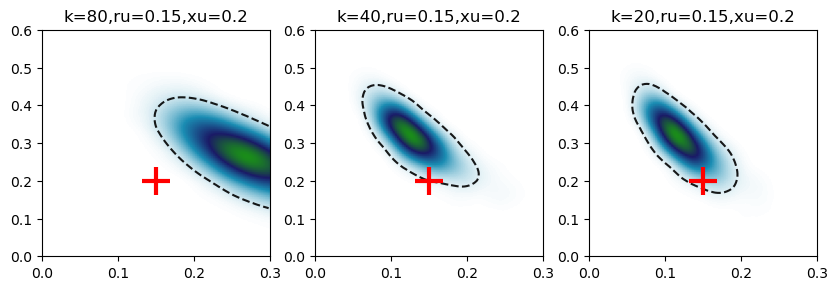

In [60]:
plt.figure(figsize=figsize)

ru_mutation = 4e-3
xu_mutation = 4e-2
samples = 3000
superstep = 100

for i, d_ in enumerate(tqdm(data)):
    plt.subplot(nrows, ncols, i+1)
    f = 1 if i < 3 else 10
    
    inference(d_, n_samples=samples, ru_mutation=ru_mutation*f, xu_mutation=xu_mutation*f, superstep=superstep)
    plot_posterior_samples_kde(d_, color='b', alpha=0.5, bandwidth=1)

    ru = d_['ru']
    xu = d_['xu']
    #plt.xlim((0*ru,2.5*ru))
    #plt.ylim((0.5*xu,3.5*xu))
    plt.title(f"k={d_['stiffness']},ru={d_['ru']},xu={d_['xu']}")